# C02e2 — RAID-only FZ-118 feature-guided interventions

This notebook begins the intervention stage from the corrected detector contract.
It uses RAID only: Ghostbuster is excluded from training, calibration, selection,
contribution analysis, and outcomes because its paragraph and parenthesis artifacts
made it an unsuitable benchmark for this experiment.

## Frozen design

- use only non-adversarial RAID native human–AI pairs;
- replace newlines with spaces for every text before FZ-118 extraction;
- exclude the four left/right-parenthesis coordinates;
- calibrate 95% and 99% specificity on RAID validation humans only;
- select eight RAID test AI cases before any rewrite exists;
- request exactly one feature-guided rewrite per case;
- evaluate every returned treatment without outcome-based candidate selection;
- preserve meaning, named entities, and numbers as explicit diagnostics.

The eight-case experiment is a causal micro-study and does not authorize a larger
run automatically.


In [1]:
from pathlib import Path
from collections import Counter
from difflib import SequenceMatcher
import hashlib
import importlib.util
import json
import pickle
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from sklearn.base import clone
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
)

ROOT = Path("..")
C02D2_OUT = ROOT / "results" / "causal" / "C02d2_fz118_ghostbuster_raid"
OUT = ROOT / "results" / "causal" / "C02e2_raid_feature_guided"
INBOX = OUT / "candidate_inbox"
OUT.mkdir(parents=True, exist_ok=True)
INBOX.mkdir(parents=True, exist_ok=True)

SEED = 42
CASES_PER_BAND = 4
TARGET_SPECIFICITIES = (0.95, 0.99)
SEMANTIC_COSINE_FLOOR = 0.90
LAYOUT_NORMALIZATION_VERSION = "newline_to_space_v1"

PARENTHESIS_FEATURES = [
    "punct_relative_lparen",
    "punct_relative_rparen",
    "punct_per_sentence_lparen",
    "punct_per_sentence_rparen",
]

print("output:", OUT)
print("micro cases:", 2 * CASES_PER_BAND)
print("specificity targets:", TARGET_SPECIFICITIES)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


output: ../results/causal/C02e2_raid_feature_guided
micro cases: 8
specificity targets: (0.95, 0.99)


## 1. Dependencies and exact FZ-118 resources

This notebook does not generate rewrites. It exports a CSV contract so generation
remains isolated and resumable. The semantic model is loaded only after completed
treatments exist.


In [2]:
required = {
    "spacy": "spacy",
    "textstat": "textstat",
    "sentence_transformers": "sentence-transformers",
    "pyarrow": "pyarrow",
    "requests": "requests",
}
missing = [
    pip_name
    for module, pip_name in required.items()
    if importlib.util.find_spec(module) is None
]
if missing:
    print("Run this once in the current kernel, restart, and rerun:")
    print("%pip install " + " ".join(sorted(set(missing))))
    raise RuntimeError("Missing packages: " + ", ".join(missing))

import requests
import spacy
import textstat

try:
    nlp = spacy.load("en_core_web_sm")
except OSError as exc:
    print("Run once, restart the kernel, and rerun:")
    print("!python -m spacy download en_core_web_sm")
    raise exc

PUNCTUATION = [
    ("comma", ","), ("period", "."), ("colon", ":"), ("semicolon", ";"),
    ("question", "?"), ("exclamation", "!"), ("hyphen", "-"),
    ("quote", '"'), ("lparen", "("), ("rparen", ")"),
    ("lbracket", "["), ("rbracket", "]"), ("newline", "\n"),
]

GOOGLE_WORDS_PATH = C02D2_OUT / "google-10000-english.txt"
GOOGLE_WORDS_URL = (
    "https://raw.githubusercontent.com/first20hours/"
    "google-10000-english/master/google-10000-english.txt"
)
if not GOOGLE_WORDS_PATH.exists():
    response = requests.get(GOOGLE_WORDS_URL, timeout=60)
    response.raise_for_status()
    GOOGLE_WORDS_PATH.write_bytes(response.content)

google_words = [
    line.strip().lower()
    for line in GOOGLE_WORDS_PATH.read_text(encoding="utf-8").splitlines()
    if line.strip()
]
GOOGLE_TOP = {
    100: set(google_words[:100]),
    1000: set(google_words[:1000]),
    10000: set(google_words[:10000]),
}
print("dependencies ready")


dependencies ready


## 2. Load and enforce the RAID-only detector contract

The already selected ExtraTrees family is fitted on RAID training rows only.
RAID validation remains outside model fitting so it can calibrate operating
thresholds; RAID test remains untouched until evaluation and case selection.


In [3]:
paths = {
    "feature_contract": C02D2_OUT / "fz118_feature_contract.json",
    "features": C02D2_OUT / "fz118_paired_features.parquet",
    "corpus": C02D2_OUT / "paired_corpus.parquet",
    "pair_table": C02D2_OUT / "native_pair_table.parquet",
    "source_manifest": C02D2_OUT / "paired_detector_manifest.json",
    "candidate_detector": C02D2_OUT / "fz118_raid_detector.pkl",
}
status = pd.DataFrame([
    {"artifact": name, "path": str(path), "exists": path.exists()}
    for name, path in paths.items()
])
display(status)

required_artifacts = [
    "feature_contract", "features", "corpus", "pair_table", "source_manifest"
]
missing_artifacts = [name for name in required_artifacts if not paths[name].exists()]
if missing_artifacts:
    raise FileNotFoundError("Missing C02d2 artifacts: " + ", ".join(missing_artifacts))

with paths["feature_contract"].open() as handle:
    feature_contract = json.load(handle)
with paths["source_manifest"].open() as handle:
    source_manifest = json.load(handle)

FEATURE_NAMES = list(feature_contract["feature_names"])
FEATURE_BLOCKS = {
    name: list(indices)
    for name, indices in feature_contract["feature_blocks"].items()
}
MODEL_FEATURES = [
    name for name in FEATURE_NAMES if name not in PARENTHESIS_FEATURES
]

if len(FEATURE_NAMES) != 118 or len(MODEL_FEATURES) != 114:
    raise ValueError("Expected the 118-feature contract and 114-feature final model.")
if source_manifest.get("raid_selected_adversarial_rows") != 0:
    raise RuntimeError("RAID adversarial exclusion is not proven by the source manifest.")

features_all = pd.read_parquet(paths["features"])
corpus_all = pd.read_parquet(paths["corpus"])
pair_table_all = pd.read_parquet(paths["pair_table"])

features = features_all[features_all["dataset"].eq("raid")].copy()
corpus = corpus_all[corpus_all["dataset"].eq("raid")].copy()
pair_table = pair_table_all[pair_table_all["dataset"].eq("raid")].copy()

assert len(features) > 0 and len(corpus) > 0 and len(pair_table) > 0
assert features["dataset"].eq("raid").all()
assert corpus["dataset"].eq("raid").all()
assert features["n_paragraphs"].eq(1).all()
assert features["punct_relative_newline"].eq(0).all()
assert features["punct_per_sentence_newline"].eq(0).all()

raid_train = features[features["split"].eq("train")].copy()
raid_validation = features[features["split"].eq("validation")].copy()
raid_test = features[features["split"].eq("test")].copy()
print("fitting the frozen RAID-only no-parentheses ExtraTrees detector")
raid_detector = ExtraTreesClassifier(
    n_estimators=600,
    min_samples_leaf=3,
    max_features="sqrt",
    n_jobs=-1,
    random_state=SEED,
)
raid_detector.fit(raid_train[MODEL_FEATURES], raid_train["label"])

FINAL_DETECTOR_PATH = OUT / "fz118_raid_no_parentheses_detector.pkl"
with FINAL_DETECTOR_PATH.open("wb") as handle:
    pickle.dump(raid_detector, handle)
(OUT / "fz118_raid_model_features.json").write_text(
    json.dumps(MODEL_FEATURES, indent=2) + "\n",
    encoding="utf-8",
)

print("RAID rows by split/class:")
display(features.groupby(["split", "class_name"]).size().rename("n").to_frame())
print("final model features:", len(MODEL_FEATURES))


,artifact,path,exists
0,feature_contract,/home/user/Downloads/TemporalContextResearch/...,True
1,features,/home/user/Downloads/TemporalContextResearch/...,True
2,corpus,/home/user/Downloads/TemporalContextResearch/...,True
3,pair_table,/home/user/Downloads/TemporalContextResearch/...,True
4,source_manifest,/home/user/Downloads/TemporalContextResearch/...,True
5,candidate_detector,/home/user/Downloads/TemporalContextResearch/...,True


fitting the frozen RAID-only no-parentheses ExtraTrees detector
RAID rows by split/class:


n
split      class_name     
test       ai          138
           human       138
train      ai          636
           human       636
validation ai          135
           human       135

final model features: 114


## 3. Exact FZ-118 extraction with class-blind layout normalization

Candidate rewrites use the same extractor and preprocessing as detector training.


In [4]:
def safe_div(a, b):
    return float(a) / float(b) if b else 0.0


def clean_word_tokens(span):
    return [
        token.text.lower()
        for token in span
        if token.is_alpha
    ]


def clean_pos_tokens(span):
    return [
        token.pos_
        for token in span
        if token.is_alpha
    ]


def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(
        tuple(sequence[i:i+n])
        for i in range(len(sequence) - n + 1)
    )


def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    shared = sum((a & b).values())
    return float(shared / denominator)


def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)

    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]

    # Include 1.0 in the final bin.
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))


def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(
                    multiset_overlap(words[:i], words[i+1:], n)
                )
    return float(np.mean(values)) if values else 0.0


def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)


def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0


def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector


toy = "One short sentence. Another sentence repeats one short phrase, and one short phrase returns."
toy_vector = extract_fz118(toy)
assert toy_vector.shape == (118,)
print("FZ-118 extractor smoke test passed")


FZ-118 extractor smoke test passed


In [5]:
def normalize_detector_text(text):
    return str(text).translate(str.maketrans({"\n": " ", "\r": " "}))


# Verify the downstream extractor against one cached RAID row.
smoke_row = features.iloc[0]
smoke_text = corpus.loc[
    corpus["source_id"].eq(smoke_row["source_id"]), "text"
].iloc[0]
recomputed = extract_fz118(normalize_detector_text(smoke_text))
cached = smoke_row[FEATURE_NAMES].to_numpy(float)
extractor_error = float(np.max(np.abs(recomputed - cached)))
print("maximum extractor contract error:", extractor_error)
assert extractor_error < 1e-9


maximum extractor contract error: 0.0


## 4. RAID-only operating points

Thresholds are quantiles of RAID validation-human probabilities. RAID test remains
the only operating-point evaluation set.


In [6]:
validation_probability = raid_detector.predict_proba(
    raid_validation[MODEL_FEATURES]
)[:, 1]
test_probability = raid_detector.predict_proba(raid_test[MODEL_FEATURES])[:, 1]

validation_label = raid_validation["label"].to_numpy(int)
test_label = raid_test["label"].to_numpy(int)
validation_human_probability = validation_probability[validation_label == 0]

thresholds = {
    specificity: float(np.quantile(validation_human_probability, specificity))
    for specificity in TARGET_SPECIFICITIES
}

operating_rows = []
for specificity, threshold in thresholds.items():
    operating_rows.append({
        "human_specificity_target": specificity,
        "validation_human_threshold": threshold,
        "raid_test_human_false_positive_rate": float(
            np.mean(test_probability[test_label == 0] >= threshold)
        ),
        "raid_test_ai_recall": float(
            np.mean(test_probability[test_label == 1] >= threshold)
        ),
        "selected_raid_test_ai": int(
            np.sum((test_label == 1) & (test_probability >= threshold))
        ),
        "total_raid_test_ai": int(np.sum(test_label == 1)),
    })

operating_summary = pd.DataFrame(operating_rows)
display(operating_summary)
operating_summary.to_csv(OUT / "raid_operating_points_p95_p99.csv", index=False)

raid_test_probability = raid_test[
    ["source_id", "pair_id", "domain", "generator", "label", "class_name"]
].copy()
raid_test_probability["ai_probability"] = test_probability


,human_specificity_target,validation_human_threshold,raid_test_human_false_positive_rate,raid_test_ai_recall,selected_raid_test_ai,total_raid_test_ai
0,0.95,0.588892,0.050725,0.456522,63,138
1,0.99,0.649258,0.014493,0.260870,36,138


## 5. Exact RAID-only contribution differences at 95% and 99% specificity

Exact tree-path contributions sum to the model probability. The graph compares the
median selected RAID AI contribution with the median RAID test-human contribution.


RAID exact contributions: 100%|█| 600/600 [00:06<00


maximum reconstruction error: 1.2212453270876722e-15


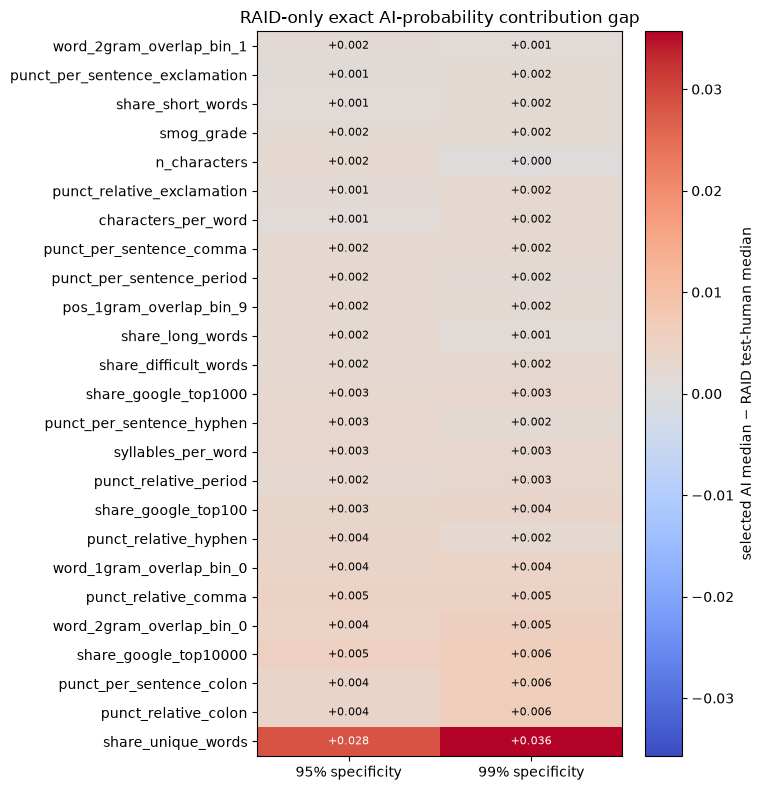

,feature,p95,p99,max_absolute_gap
23,share_unique_words,0.028326,0.035699,0.035699
29,punct_relative_colon,0.003799,0.006238,0.006238
40,punct_per_sentence_colon,0.003866,0.006093,0.006093
26,share_google_top10000,0.005134,0.005979,0.005979
61,word_2gram_overlap_bin_0,0.004372,0.005394,0.005394
27,punct_relative_comma,0.004670,0.004565,0.004670
51,word_1gram_overlap_bin_0,0.004081,0.004233,0.004233
33,punct_relative_hyphen,0.003847,0.002231,0.003847
24,share_google_top100,0.003395,0.003664,0.003664
28,punct_relative_period,0.002320,0.003304,0.003304


In [7]:
def exact_forest_probability_contributions(detector, frame, feature_names, desc):
    X_frame = frame[feature_names]
    X = np.asarray(X_frame, dtype=np.float32)
    classes = np.asarray(detector.classes_)
    ai_positions = np.flatnonzero(classes == 1)
    if len(ai_positions) != 1:
        raise ValueError(f"Could not identify AI class 1 in {classes}")
    ai_position = int(ai_positions[0])

    contributions = np.zeros((len(X), len(feature_names)), dtype=float)
    root_bias = 0.0

    for estimator in tqdm(detector.estimators_, desc=desc):
        tree = estimator.tree_
        values = tree.value[:, 0, :].astype(float)
        totals = values.sum(axis=1)
        node_probability = np.divide(
            values[:, ai_position], totals,
            out=np.zeros(len(values), dtype=float), where=totals != 0,
        )
        path = estimator.decision_path(X)
        root_bias += node_probability[0]

        for row_index in range(len(X)):
            nodes = path.indices[path.indptr[row_index]:path.indptr[row_index + 1]]
            for parent in nodes:
                feature_index = tree.feature[parent]
                if feature_index < 0:
                    continue
                child = (
                    tree.children_left[parent]
                    if X[row_index, feature_index] <= tree.threshold[parent]
                    else tree.children_right[parent]
                )
                contributions[row_index, feature_index] += (
                    node_probability[child] - node_probability[parent]
                )

    root_bias /= len(detector.estimators_)
    contributions /= len(detector.estimators_)
    predicted = detector.predict_proba(X_frame)[:, 1]
    reconstructed = root_bias + contributions.sum(axis=1)
    error = float(np.max(np.abs(predicted - reconstructed)))
    print("maximum reconstruction error:", error)
    assert error < 1e-8
    return root_bias, contributions, predicted


explanation_frame = pd.concat([raid_validation, raid_test], ignore_index=True)
root_bias, all_contributions, all_probability = (
    exact_forest_probability_contributions(
        raid_detector, explanation_frame, MODEL_FEATURES,
        "RAID exact contributions",
    )
)

n_validation = len(raid_validation)
validation_contributions = all_contributions[:n_validation]
test_contributions = all_contributions[n_validation:]
validation_probability = all_probability[:n_validation]
test_probability = all_probability[n_validation:]

human_reference = np.median(test_contributions[test_label == 0], axis=0)
gap_columns = {}
for specificity, threshold in thresholds.items():
    selected_ai = (test_label == 1) & (test_probability >= threshold)
    if not selected_ai.any():
        raise RuntimeError(f"No RAID test AI rows exceed {specificity:.0%} specificity.")
    gap_columns[f"p{int(specificity * 100)}"] = (
        np.median(test_contributions[selected_ai], axis=0) - human_reference
    )

contribution_gap = pd.DataFrame({"feature": MODEL_FEATURES, **gap_columns})
contribution_gap["max_absolute_gap"] = contribution_gap[["p95", "p99"]].abs().max(axis=1)
plot_table = (
    contribution_gap.sort_values("max_absolute_gap", ascending=False)
    .head(25).sort_values("max_absolute_gap").reset_index(drop=True)
)

matrix = plot_table[["p95", "p99"]].to_numpy()
limit = float(np.abs(matrix).max())
fig, axis = plt.subplots(figsize=(7.5, max(7, 0.32 * len(plot_table))))
image = axis.imshow(
    matrix, aspect="auto", cmap="coolwarm", vmin=-limit, vmax=limit
)
axis.set_xticks([0, 1], ["95% specificity", "99% specificity"])
axis.set_yticks(np.arange(len(plot_table)), plot_table["feature"])
axis.set_title("RAID-only exact AI-probability contribution gap")
for row_index in range(matrix.shape[0]):
    for column_index in range(matrix.shape[1]):
        value = matrix[row_index, column_index]
        color = "white" if abs(value) > 0.55 * limit else "black"
        axis.text(
            column_index, row_index, f"{value:+.3f}",
            ha="center", va="center", color=color, fontsize=8,
        )
colorbar = fig.colorbar(image, ax=axis)
colorbar.set_label("selected AI median − RAID test-human median")
fig.tight_layout()
contribution_figure = OUT / "raid_exact_contribution_gap_p95_p99.png"
fig.savefig(contribution_figure, dpi=200, bbox_inches="tight")
plt.show()

contribution_gap.to_csv(
    OUT / "raid_exact_contribution_gap_p95_p99.csv", index=False
)
display(contribution_gap.sort_values("max_absolute_gap", ascending=False).head(25))


## 6. Freeze eight held-out RAID AI cases

Four cases are sampled just above the 99%-specificity boundary and four from the
95–99% band. Selection prefers distinct domains and proximity to the relevant
boundary. It never examines a rewrite because none exists yet.


In [8]:
ai_test = raid_test_probability[raid_test_probability["label"].eq(1)].copy()
threshold_95 = thresholds[0.95]
threshold_99 = thresholds[0.99]
ai_test["score_band"] = np.select(
    [
        ai_test["ai_probability"].ge(threshold_99),
        ai_test["ai_probability"].ge(threshold_95),
    ],
    ["p99", "p95_to_p99"],
    default="below_p95",
)

def choose_diverse_near_boundary(pool, threshold, n, used_source_ids=None):
    used_source_ids = set() if used_source_ids is None else set(used_source_ids)
    candidates = pool[~pool["source_id"].isin(used_source_ids)].copy()
    candidates["boundary_distance"] = (
        candidates["ai_probability"] - threshold
    ).abs()
    candidates = candidates.sort_values(
        ["boundary_distance", "domain", "source_id"]
    )
    chosen_indices = []
    used_domains = set()
    for index, row in candidates.iterrows():
        if row["domain"] not in used_domains:
            chosen_indices.append(index)
            used_domains.add(row["domain"])
        if len(chosen_indices) == n:
            break
    if len(chosen_indices) < n:
        remaining = candidates[~candidates.index.isin(chosen_indices)]
        chosen_indices.extend(remaining.head(n - len(chosen_indices)).index.tolist())
    return candidates.loc[chosen_indices].copy()

selected_99 = choose_diverse_near_boundary(
    ai_test[ai_test["score_band"].eq("p99")],
    threshold_99,
    CASES_PER_BAND,
)
selected_95 = choose_diverse_near_boundary(
    ai_test[ai_test["score_band"].eq("p95_to_p99")],
    threshold_95,
    CASES_PER_BAND,
    used_source_ids=selected_99["source_id"],
)

micro_cases = pd.concat([selected_99, selected_95], ignore_index=True)
if len(micro_cases) != 2 * CASES_PER_BAND:
    raise RuntimeError(
        "Insufficient distinct RAID AI cases in the frozen p95/p99 bands."
    )
assert micro_cases["source_id"].is_unique
assert micro_cases["label"].eq(1).all()
assert micro_cases["source_id"].isin(raid_test["source_id"]).all()

micro_cases = micro_cases.sort_values(
    ["score_band", "ai_probability", "source_id"],
    ascending=[False, True, True],
).reset_index(drop=True)
micro_cases["case_id"] = [f"raid_micro_{index:02d}" for index in range(1, len(micro_cases) + 1)]

selection_payload = micro_cases[
    ["case_id", "source_id", "pair_id", "domain", "generator", "score_band"]
].to_csv(index=False)
SELECTION_SHA256 = hashlib.sha256(selection_payload.encode("utf-8")).hexdigest()
micro_cases["selection_sha256"] = SELECTION_SHA256

micro_cases.to_csv(OUT / "raid_micro_selection.csv", index=False)
display(micro_cases)
print("selection SHA256:", SELECTION_SHA256)


,source_id,pair_id,domain,generator,label,class_name,ai_probability,score_band,boundary_distance,case_id,selection_sha256
0,ai__raid:fcd2c78e-c388-46be-9a2d-7a9cb77381ea,1530,recipes,llama-chat,1,ai,0.649867,p99,0.000609,raid_micro_01,30199fcc27d5b279ba98096f50d50e36b654ac06d93d77...
1,ai__raid:2737d3fd-1ed6-40ae-acb9-d1af0baf5b7c,755,wiki,mistral,1,ai,0.651501,p99,0.002243,raid_micro_02,30199fcc27d5b279ba98096f50d50e36b654ac06d93d77...
2,ai__raid:25689644-8159-4de0-8167-2efea735f75b,745,reddit,mpt-chat,1,ai,0.660483,p99,0.011225,raid_micro_03,30199fcc27d5b279ba98096f50d50e36b654ac06d93d77...
3,ai__raid:140bcdd4-cb85-49b7-ad40-483a21380193,699,news,gpt4,1,ai,0.660908,p99,0.011650,raid_micro_04,30199fcc27d5b279ba98096f50d50e36b654ac06d93d77...
4,ai__raid:e9f78f95-8a2d-4a0a-a47a-044c9c6c5c22,1471,reddit,mistral-chat,1,ai,0.590246,p95_to_p99,0.001354,raid_micro_05,30199fcc27d5b279ba98096f50d50e36b654ac06d93d77...
5,ai__raid:efc8537a-8575-4af0-aae5-a06bc4bccc04,1485,books,llama-chat,1,ai,0.590607,p95_to_p99,0.001715,raid_micro_06,30199fcc27d5b279ba98096f50d50e36b654ac06d93d77...
6,ai__raid:0f754d71-62ae-4f45-9e67-7c835bc8ebe1,681,poetry,gpt4,1,ai,0.591105,p95_to_p99,0.002213,raid_micro_07,30199fcc27d5b279ba98096f50d50e36b654ac06d93d77...
7,ai__raid:3bc610dd-010e-480c-8af3-1c5da8728644,836,abstracts,mistral-chat,1,ai,0.593705,p95_to_p99,0.004813,raid_micro_08,30199fcc27d5b279ba98096f50d50e36b654ac06d93d77...


selection SHA256: 30199fcc27d5b279ba98096f50d50e36b654ac06d93d77b29503e8e079664ed5


## 7. Convert exact contribution gaps into frozen rewrite requests

Each case receives one request targeting its three largest positive contribution
gaps from the median RAID validation human, with duplicate feature blocks collapsed.
The request never exposes a detector score to the rewriting model.


In [9]:
feature_to_block = {
    FEATURE_NAMES[index]: block
    for block, indices in FEATURE_BLOCKS.items()
    for index in indices
}

validation_human = raid_validation[
    raid_validation["label"].eq(0)
].copy()

validation_human_contribution = validation_contributions[
    validation_label == 0
]

median_human_contribution = np.median(
    validation_human_contribution,
    axis=0,
)

median_human_value = validation_human[
    MODEL_FEATURES
].median()

micro_feature_rows = (
    raid_test
    .set_index("source_id")
    .loc[micro_cases["source_id"]]
    .reset_index()
)

raid_test_position = (
    raid_test
    .reset_index(drop=True)
    .reset_index()
    .set_index("source_id")
)

micro_indices = raid_test_position.loc[
    micro_cases["source_id"],
    "index",
].to_numpy(int)

micro_contributions = test_contributions[
    micro_indices
]


def control_family(feature, block):
    """Collapse redundant representations of the same intervention."""

    if feature.startswith("punct_"):
        punctuation = feature.rsplit("_", 1)[-1]
        return ("punctuation", punctuation)

    if feature.startswith("share_google_top"):
        return ("common_vocabulary",)

    if feature in {
        "share_unique_words",
        "share_short_words",
        "share_long_words",
        "share_difficult_words",
    }:
        return ("lexical_composition", feature)

    return (block,)


def natural_instruction(feature, value, human_value):
    direction = (
        "reduce"
        if value > human_value
        else "increase"
    )

    if feature == "share_unique_words":
        return (
            "Reuse important content words slightly more instead of "
            "continually introducing synonyms."
            if direction == "reduce"
            else
            "Use somewhat more varied wording while keeping every "
            "claim unchanged."
        )

    if feature.startswith("share_google_top"):
        return (
            "Replace a few generic high-frequency words with more "
            "precise alternatives."
            if direction == "reduce"
            else
            "Prefer slightly more common everyday wording where the "
            "meaning is unchanged."
        )

    if "long_words" in feature or "difficult_words" in feature:
        return (
            "Prefer shorter, more common words where they express the "
            "same meaning."
            if direction == "reduce"
            else
            "Use a few more precise content words where natural."
        )

    if feature in {
        "characters_per_word",
        "syllables_per_word",
    }:
        return (
            "Prefer shorter word forms where natural."
            if direction == "reduce"
            else
            "Use slightly more specific word choices where natural."
        )

    if feature == "words_per_sentence":
        return (
            "Break up some long sentences without changing their content."
            if direction == "reduce"
            else
            "Combine a few closely related short sentences where natural."
        )

    if feature == "n_sentences":
        return (
            "Combine a few closely related sentences where natural."
            if direction == "reduce"
            else
            "Break up a few long sentences while preserving their content."
        )

    if feature.startswith("punct_"):
        punctuation_name = feature.rsplit("_", 1)[-1]

        punctuation_labels = {
            "comma": "commas",
            "period": "periods",
            "colon": "colons",
            "semicolon": "semicolons",
            "question": "question marks",
            "exclamation": "exclamation marks",
            "hyphen": "hyphens",
            "quote": "quotation marks",
            "lbracket": "square brackets",
            "rbracket": "square brackets",
        }

        label = punctuation_labels.get(
            punctuation_name,
            punctuation_name,
        )

        if punctuation_name in {"lbracket", "rbracket"}:
            return (
                "Convert bracketed material into ordinary prose where "
                "possible, without deleting its content."
                if direction == "reduce"
                else
                "Use a brief bracketed clarification only where it "
                "improves precision."
            )

        return (
            f"Reduce grammatically optional {label} while preserving "
            "sentence meaning."
            if direction == "reduce"
            else
            f"Use slightly more {label} where grammatically natural."
        )

    if feature.startswith("pos_") and "overlap" in feature:
        return (
            "Vary the grammatical structure of adjacent sentences while "
            "preserving their meaning."
            if direction == "reduce"
            else
            "Use somewhat more consistent grammatical structure across "
            "adjacent sentences."
        )

    if feature.startswith("word_") and "overlap" in feature:
        return (
            "Reduce repetitive adjacent-sentence phrasing while preserving "
            "cohesion."
            if direction == "reduce"
            else
            "Repeat important terms across adjacent sentences to strengthen "
            "lexical continuity."
        )

    if "conjunction" in feature and "overlap" in feature:
        return (
            "Vary phrasing around conjunctions without changing the logical "
            "relationships."
            if direction == "reduce"
            else
            "Make connected clauses reuse their important terms slightly "
            "more consistently."
        )

    if feature in {
        "flesch_reading_ease",
        "flesch_kincaid_grade",
        "coleman_liau_index",
        "gunning_fog",
        "lix",
        "rix",
        "smog_grade",
        "mcalpine_eflaw",
    }:
        return (
            "Make sentence structure slightly simpler and more direct."
            if direction == "reduce"
            else
            "Allow slightly more varied sentence structure without "
            "adding detail."
        )

    return (
        f"Move {feature} modestly toward the reference style without "
        "changing the passage's content."
    )


routing_rows = []
request_rows = []

corpus_text = (
    corpus
    .set_index("source_id")["text"]
    .astype(str)
)

for row_index, case in micro_cases.iterrows():
    gaps = (
        micro_contributions[row_index]
        - median_human_contribution
    )

    ordered_feature_indices = np.argsort(gaps)[::-1]

    chosen = []
    used_controls = set()

    for feature_index in ordered_feature_indices:
        if gaps[feature_index] <= 0:
            continue

        feature = MODEL_FEATURES[feature_index]
        block = feature_to_block[feature]
        control = control_family(feature, block)

        if control in used_controls:
            continue

        chosen.append({
            "feature_index": feature_index,
            "feature": feature,
            "feature_block": block,
            "exact_contribution_gap": float(
                gaps[feature_index]
            ),
        })

        used_controls.add(control)

        if len(chosen) == 3:
            break

    if len(chosen) != 3:
        raise RuntimeError(
            f"Could not identify three independent controls for "
            f"{case['case_id']}."
        )

    instructions = []

    for rank, target in enumerate(chosen, start=1):
        feature = target["feature"]
        value = float(
            micro_feature_rows.iloc[row_index][feature]
        )
        human_value = float(
            median_human_value[feature]
        )

        instruction = natural_instruction(
            feature,
            value,
            human_value,
        )
        instructions.append(instruction)

        routing_rows.append({
            "case_id": case["case_id"],
            "source_id": case["source_id"],
            "rank": rank,
            "feature": feature,
            "feature_block": target["feature_block"],
            "control_family": repr(
                control_family(
                    feature,
                    target["feature_block"],
                )
            ),
            "exact_contribution_gap": (
                target["exact_contribution_gap"]
            ),
            "source_value": value,
            "raid_validation_human_median": human_value,
            "requested_direction": (
                "reduce"
                if value > human_value
                else "increase"
            ),
            "instruction": instruction,
        })

    input_text = corpus_text.loc[
        case["source_id"]
    ]

    prompt = (
        "Rewrite the passage once. Preserve every fact, number, "
        "named entity, and the overall meaning. Do not add headings, "
        "bullets, commentary, or new facts. Return only the rewritten "
        "passage. Apply these modest style adjustments:\n- "
        + "\n- ".join(instructions)
        + "\n\nPASSAGE:\n"
        + input_text
    )

    request_rows.append({
        "case_id": case["case_id"],
        "source_id": case["source_id"],
        "pair_id": case["pair_id"],
        "domain": case["domain"],
        "generator": case["generator"],
        "score_band": case["score_band"],
        "selection_sha256": SELECTION_SHA256,
        "input_text": input_text,
        "rewrite_prompt": prompt,
        "output_text": "",
    })


routing = pd.DataFrame(routing_rows)
requests_frame = pd.DataFrame(request_rows)

# Freeze the exact prompts separately from the case-selection hash.
request_payload = requests_frame[
    [
        "case_id",
        "source_id",
        "selection_sha256",
        "rewrite_prompt",
    ]
].to_csv(index=False)

REQUEST_SHA256 = hashlib.sha256(
    request_payload.encode("utf-8")
).hexdigest()

requests_frame["request_sha256"] = REQUEST_SHA256
routing["request_sha256"] = REQUEST_SHA256

REQUEST_PATH = (
    INBOX
    / "raid_feature_guided_requests.csv"
)

# Preserve already completed outputs only if they belong to the
# same frozen selection and exact prompt contract.
if REQUEST_PATH.exists():
    previous = pd.read_csv(
        REQUEST_PATH,
        keep_default_na=False,
    )

    compatible_previous = (
        {"source_id", "output_text", "selection_sha256",
         "request_sha256"}.issubset(previous.columns)
        and previous["selection_sha256"].eq(
            SELECTION_SHA256
        ).all()
        and previous["request_sha256"].eq(
            REQUEST_SHA256
        ).all()
    )

    if compatible_previous:
        previous_output = (
            previous
            .set_index("source_id")["output_text"]
            .to_dict()
        )

        requests_frame["output_text"] = (
            requests_frame["source_id"]
            .map(previous_output)
            .fillna("")
        )

routing.to_csv(
    OUT / "raid_micro_routing.csv",
    index=False,
)

requests_frame.to_csv(
    REQUEST_PATH,
    index=False,
)

display(routing)

display(
    requests_frame[
        [
            "case_id",
            "source_id",
            "domain",
            "generator",
            "score_band",
            "output_text",
        ]
    ]
)

print("selection SHA256:", SELECTION_SHA256)
print("request SHA256:", REQUEST_SHA256)
print("rewrite request:", REQUEST_PATH)

,case_id,source_id,rank,feature,feature_block,control_family,exact_contribution_gap,source_value,raid_validation_human_median,requested_direction,instruction,request_sha256
0,raid_micro_01,ai__raid:fcd2c78e-c388-46be-9a2d-7a9cb77381ea,1,punct_relative_colon,punctuation_relative,"('punctuation', 'colon')",0.068639,0.001908,0.000000,reduce,Reduce grammatically optional colons while pre...,01b3d5420b14e8b1566ca32c1480aaa71442d8d273e164...
1,raid_micro_01,ai__raid:fcd2c78e-c388-46be-9a2d-7a9cb77381ea,2,word_2gram_overlap_bin_0,word_sentence_overlap,"('word_sentence_overlap',)",0.014849,0.714286,0.900000,increase,Repeat important terms across adjacent sentenc...,01b3d5420b14e8b1566ca32c1480aaa71442d8d273e164...
2,raid_micro_01,ai__raid:fcd2c78e-c388-46be-9a2d-7a9cb77381ea,3,punct_relative_comma,punctuation_relative,"('punctuation', 'comma')",0.009611,0.013359,0.007752,reduce,Reduce grammatically optional commas while pre...,01b3d5420b14e8b1566ca32c1480aaa71442d8d273e164...
3,raid_micro_02,ai__raid:2737d3fd-1ed6-40ae-acb9-d1af0baf5b7c,1,punct_per_sentence_rbracket,punctuation_per_sentence,"('punctuation', 'rbracket')",0.055290,0.428571,0.000000,reduce,Convert bracketed material into ordinary prose...,01b3d5420b14e8b1566ca32c1480aaa71442d8d273e164...
4,raid_micro_02,ai__raid:2737d3fd-1ed6-40ae-acb9-d1af0baf5b7c,2,punct_per_sentence_lbracket,punctuation_per_sentence,"('punctuation', 'lbracket')",0.045265,0.428571,0.000000,reduce,Convert bracketed material into ordinary prose...,01b3d5420b14e8b1566ca32c1480aaa71442d8d273e164...
5,raid_micro_02,ai__raid:2737d3fd-1ed6-40ae-acb9-d1af0baf5b7c,3,punct_per_sentence_colon,punctuation_per_sentence,"('punctuation', 'colon')",0.006665,0.071429,0.000000,reduce,Reduce grammatically optional colons while pre...,01b3d5420b14e8b1566ca32c1480aaa71442d8d273e164...
6,raid_micro_03,ai__raid:25689644-8159-4de0-8167-2efea735f75b,1,punct_relative_exclamation,punctuation_relative,"('punctuation', 'exclamation')",0.035116,0.003322,0.000000,reduce,Reduce grammatically optional exclamation mark...,01b3d5420b14e8b1566ca32c1480aaa71442d8d273e164...
7,raid_micro_03,ai__raid:25689644-8159-4de0-8167-2efea735f75b,2,share_unique_words,lexical_diversity,"('lexical_composition', 'share_unique_words')",0.034460,0.738318,0.570707,reduce,Reuse important content words slightly more in...,01b3d5420b14e8b1566ca32c1480aaa71442d8d273e164...
8,raid_micro_03,ai__raid:25689644-8159-4de0-8167-2efea735f75b,3,share_google_top10000,lexical_diversity,"('common_vocabulary',)",0.019059,0.943925,0.886010,reduce,Replace a few generic high-frequency words wit...,01b3d5420b14e8b1566ca32c1480aaa71442d8d273e164...
9,raid_micro_04,ai__raid:140bcdd4-cb85-49b7-ad40-483a21380193,1,punct_per_sentence_exclamation,punctuation_per_sentence,"('punctuation', 'exclamation')",0.038565,0.071429,0.000000,reduce,Reduce grammatically optional exclamation mark...,01b3d5420b14e8b1566ca32c1480aaa71442d8d273e164...


,case_id,source_id,domain,generator,score_band,output_text
0,raid_micro_01,ai__raid:fcd2c78e-c388-46be-9a2d-7a9cb77381ea,recipes,llama-chat,p99,
1,raid_micro_02,ai__raid:2737d3fd-1ed6-40ae-acb9-d1af0baf5b7c,wiki,mistral,p99,
2,raid_micro_03,ai__raid:25689644-8159-4de0-8167-2efea735f75b,reddit,mpt-chat,p99,
3,raid_micro_04,ai__raid:140bcdd4-cb85-49b7-ad40-483a21380193,news,gpt4,p99,
4,raid_micro_05,ai__raid:e9f78f95-8a2d-4a0a-a47a-044c9c6c5c22,reddit,mistral-chat,p95_to_p99,
5,raid_micro_06,ai__raid:efc8537a-8575-4af0-aae5-a06bc4bccc04,books,llama-chat,p95_to_p99,
6,raid_micro_07,ai__raid:0f754d71-62ae-4f45-9e67-7c835bc8ebe1,poetry,gpt4,p95_to_p99,
7,raid_micro_08,ai__raid:3bc610dd-010e-480c-8af3-1c5da8728644,abstracts,mistral-chat,p95_to_p99,


selection SHA256: 30199fcc27d5b279ba98096f50d50e36b654ac06d93d77b29503e8e079664ed5
request SHA256: 01b3d5420b14e8b1566ca32c1480aaa71442d8d273e164ee2e9537a8c325697e
rewrite request: ../results/causal/C02e2_raid_feature_guided/candidate_inbox/raid_feature_guided_requests.csv


In [10]:
# Paper-backed feature-guided rewrite operator:
# Mohammadi et al. (2026), arXiv:2506.04050
#
# If needed, install once in this notebook environment:
# %pip install -U openai

import os
import json
import time
import hashlib
from getpass import getpass
from datetime import datetime, timezone

import pandas as pd
from openai import (
    OpenAI,
    APIConnectionError,
    APITimeoutError,
    RateLimitError,
    InternalServerError,
)

REWRITE_MODEL = "gpt-4o-mini-2024-07-18"
REWRITE_TEMPERATURE = 0.0
REWRITE_MAX_TOKENS = 8192
MAX_TRANSIENT_ATTEMPTS = 4

# Enter the key interactively so it is not stored in the notebook.
if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass("OpenAI API key: ").strip()

if not os.environ["OPENAI_API_KEY"]:
    raise RuntimeError("OPENAI_API_KEY was not provided.")

client = OpenAI(
    api_key=os.environ["OPENAI_API_KEY"],
    timeout=180.0,
    max_retries=0,  # retries are controlled explicitly below
)

completed = pd.read_csv(REQUEST_PATH, keep_default_na=False)

required_columns = {
    "case_id",
    "source_id",
    "selection_sha256",
    "request_sha256",
    "rewrite_prompt",
    "output_text",
}
missing_columns = required_columns - set(completed.columns)
if missing_columns:
    raise RuntimeError(
        f"Request CSV is missing required columns: {sorted(missing_columns)}. "
        "Rerun the revised routing/export cell first."
    )

if completed["source_id"].duplicated().any():
    raise RuntimeError("Duplicate treatment source_id values are not allowed.")

if len(completed) != 2 * CASES_PER_BAND:
    raise RuntimeError(
        f"Expected {2 * CASES_PER_BAND} frozen cases, found {len(completed)}."
    )

if completed["selection_sha256"].nunique() != 1:
    raise RuntimeError("Mixed selection hashes in the request CSV.")

if completed["selection_sha256"].iloc[0] != SELECTION_SHA256:
    raise RuntimeError("Selection hash does not match the frozen case selection.")

if completed["request_sha256"].nunique() != 1:
    raise RuntimeError("Mixed request hashes in the request CSV.")

if completed["request_sha256"].iloc[0] != REQUEST_SHA256:
    raise RuntimeError("Request hash does not match the frozen prompt contract.")

provenance_columns = [
    "rewrite_operator",
    "rewrite_model",
    "rewrite_temperature",
    "rewrite_response_id",
    "rewrite_system_fingerprint",
    "rewrite_finish_reason",
    "rewrite_created_utc",
    "rewrite_prompt_sha256",
    "rewrite_output_sha256",
    "rewrite_prompt_tokens",
    "rewrite_completion_tokens",
    "rewrite_transport_attempts",
]

for column in provenance_columns:
    if column not in completed.columns:
        completed[column] = pd.Series(
            [""] * len(completed),
            index=completed.index,
            dtype="object",
        )

completed["output_text"] = completed["output_text"].astype(str).str.strip()

# Do not silently mix manual or differently generated treatments.
preexisting = completed["output_text"].ne("")
bad_preexisting = preexisting & (
    completed["rewrite_model"].astype(str).ne(REWRITE_MODEL)
    | completed["rewrite_operator"].astype(str).ne("openai.chat.completions")
)
if bad_preexisting.any():
    display(
        completed.loc[
            bad_preexisting,
            ["case_id", "source_id", "rewrite_operator", "rewrite_model"],
        ]
    )
    raise RuntimeError(
        "Existing output_text values lack matching frozen-operator provenance. "
        "Do not overwrite or mix treatment sources."
    )

RAW_RESPONSE_DIR = OUT / "raw_rewrite_responses"
RAW_RESPONSE_DIR.mkdir(parents=True, exist_ok=True)

transient_errors = (
    APIConnectionError,
    APITimeoutError,
    RateLimitError,
    InternalServerError,
)


def atomic_save_csv(frame, path):
    temporary_path = path.with_name(path.name + ".tmp")
    frame.to_csv(temporary_path, index=False)
    temporary_path.replace(path)


def atomic_save_json(payload, path):
    temporary_path = path.with_name(path.name + ".tmp")
    temporary_path.write_text(
        json.dumps(payload, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    temporary_path.replace(path)


def response_text(payload):
    try:
        value = payload["choices"][0]["message"]["content"]
    except (KeyError, IndexError, TypeError) as error:
        raise RuntimeError("API response did not contain rewrite text.") from error

    if not isinstance(value, str) or not value.strip():
        raise RuntimeError("API returned a blank or refused rewrite.")

    return value.strip()


def call_rewriter_once(prompt):
    for attempt in range(1, MAX_TRANSIENT_ATTEMPTS + 1):
        try:
            response = client.chat.completions.create(
                model=REWRITE_MODEL,
                messages=[
                    # No additional system prompt: this sends the exact frozen
                    # rewrite_prompt whose hash is recorded in the request CSV.
                    {"role": "user", "content": prompt},
                ],
                temperature=REWRITE_TEMPERATURE,
                max_tokens=REWRITE_MAX_TOKENS,
                n=1,
            )
            return response.model_dump(mode="json"), attempt

        except transient_errors:
            if attempt == MAX_TRANSIENT_ATTEMPTS:
                raise

            # Transport/rate-limit retry only. A received response is never
            # regenerated or selected according to its quality/detector score.
            time.sleep(2 ** (attempt - 1))


generated_count = 0
recovered_count = 0
skipped_count = 0

for row_index, row in completed.iterrows():
    if str(row["output_text"]).strip():
        skipped_count += 1
        continue

    case_id = str(row["case_id"])
    prompt = str(row["rewrite_prompt"])
    prompt_sha256 = hashlib.sha256(prompt.encode("utf-8")).hexdigest()
    raw_response_path = RAW_RESPONSE_DIR / f"{case_id}.json"

    # If the API response was already received before a notebook interruption,
    # recover that exact response instead of generating another candidate.
    if raw_response_path.exists():
        payload = json.loads(raw_response_path.read_text(encoding="utf-8"))
        transport_attempts = 0
        recovered_count += 1
    else:
        payload, transport_attempts = call_rewriter_once(prompt)
        atomic_save_json(payload, raw_response_path)
        generated_count += 1

    finish_reason = payload["choices"][0].get("finish_reason", "")
    if finish_reason != "stop":
        raise RuntimeError(
            f"{case_id} ended with finish_reason={finish_reason!r}. "
            f"The raw response was retained at {raw_response_path}; "
            "no replacement response was sampled."
        )

    rewritten_text = response_text(payload)
    output_sha256 = hashlib.sha256(
        rewritten_text.encode("utf-8")
    ).hexdigest()

    usage = payload.get("usage") or {}

    completed.at[row_index, "output_text"] = rewritten_text
    completed.at[row_index, "rewrite_operator"] = "openai.chat.completions"
    completed.at[row_index, "rewrite_model"] = REWRITE_MODEL
    completed.at[row_index, "rewrite_temperature"] = REWRITE_TEMPERATURE
    completed.at[row_index, "rewrite_response_id"] = payload.get("id", "")
    completed.at[row_index, "rewrite_system_fingerprint"] = (
        payload.get("system_fingerprint") or ""
    )
    completed.at[row_index, "rewrite_finish_reason"] = finish_reason
    completed.at[row_index, "rewrite_created_utc"] = datetime.now(
        timezone.utc
    ).isoformat()
    completed.at[row_index, "rewrite_prompt_sha256"] = prompt_sha256
    completed.at[row_index, "rewrite_output_sha256"] = output_sha256
    completed.at[row_index, "rewrite_prompt_tokens"] = usage.get(
        "prompt_tokens", ""
    )
    completed.at[row_index, "rewrite_completion_tokens"] = usage.get(
        "completion_tokens", ""
    )
    completed.at[row_index, "rewrite_transport_attempts"] = transport_attempts

    # Checkpoint after every case.
    atomic_save_csv(completed, REQUEST_PATH)

completed = pd.read_csv(REQUEST_PATH, keep_default_na=False)

display(
    completed[
        [
            "case_id",
            "domain",
            "score_band",
            "rewrite_model",
            "rewrite_finish_reason",
            "rewrite_prompt_tokens",
            "rewrite_completion_tokens",
            "rewrite_output_sha256",
        ]
    ]
)

print(
    "rewrite generation complete:",
    {
        "new_api_responses": generated_count,
        "recovered_raw_responses": recovered_count,
        "already_complete": skipped_count,
        "total_outputs": int(completed["output_text"].astype(str).str.strip().ne("").sum()),
    },
)
print("saved:", REQUEST_PATH)
print("raw responses:", RAW_RESPONSE_DIR)

OpenAI API key:  ········


,case_id,domain,score_band,rewrite_model,rewrite_finish_reason,rewrite_prompt_tokens,rewrite_completion_tokens,rewrite_output_sha256
0,raid_micro_01,recipes,p99,gpt-4o-mini-2024-07-18,stop,458,350,96f17b3c0bb39e4b79131203152294d4c2e01b58a4bf5f...
1,raid_micro_02,wiki,p99,gpt-4o-mini-2024-07-18,stop,501,361,84c3e09b035d5b1b2bd4a50894d10202ad8b117475bedf...
2,raid_micro_03,reddit,p99,gpt-4o-mini-2024-07-18,stop,222,115,aa5b63cc9eab85e5687cd5e7cc5399a831eafe041561bc...
3,raid_micro_04,news,p99,gpt-4o-mini-2024-07-18,stop,519,428,6979e78a381f91db9bf4a2703b81f49361444ae38d8596...
4,raid_micro_05,reddit,p95_to_p99,gpt-4o-mini-2024-07-18,stop,277,187,21ff252b83cc2e838dbf9fbb4a2c99f279d0f695c1ad4b...
5,raid_micro_06,books,p95_to_p99,gpt-4o-mini-2024-07-18,stop,406,317,20f94663d7ba39b76263076749fd315c3f8b08600ab90d...
6,raid_micro_07,poetry,p95_to_p99,gpt-4o-mini-2024-07-18,stop,429,329,d1881c10553f3f973b9908ec5da76744d6aa789907554e...
7,raid_micro_08,abstracts,p95_to_p99,gpt-4o-mini-2024-07-18,stop,225,125,2dd5aa589e43124bf1a83ee679ce7bce0007a60395139a...


rewrite generation complete: {'new_api_responses': 8, 'recovered_raw_responses': 0, 'already_complete': 0, 'total_outputs': 8}
saved: ../results/causal/C02e2_raid_feature_guided/candidate_inbox/raid_feature_guided_requests.csv
raw responses: ../results/causal/C02e2_raid_feature_guided/raw_rewrite_responses


## 8. Treatment barrier

Fill each `output_text` in the exported request CSV with exactly one rewrite, then
rerun from this cell. Blank or duplicate treatments stop the notebook. No best-of-N
selection is permitted.


In [11]:
completed = pd.read_csv(
    REQUEST_PATH,
    keep_default_na=False,
)

required_columns = {
    "case_id",
    "source_id",
    "selection_sha256",
    "request_sha256",
    "input_text",
    "rewrite_prompt",
    "output_text",
}

missing_columns = sorted(
    required_columns - set(completed.columns)
)

if missing_columns:
    raise RuntimeError(
        "Treatment file uses the old request contract and is missing: "
        + ", ".join(missing_columns)
        + ". Rerun the routing/export cell first."
    )

if completed["source_id"].duplicated().any():
    raise ValueError(
        "Duplicate treatment source_id values are not allowed."
    )

if len(completed) != 2 * CASES_PER_BAND:
    raise RuntimeError(
        "The treatment file no longer contains the frozen eight cases."
    )

if set(completed["source_id"]) != set(micro_cases["source_id"]):
    raise RuntimeError(
        "Treatment source IDs differ from the frozen selection."
    )

if completed["selection_sha256"].nunique() != 1:
    raise RuntimeError(
        "Mixed selection hashes in the treatment file."
    )

if completed["selection_sha256"].iloc[0] != SELECTION_SHA256:
    raise RuntimeError(
        "Treatment selection does not match the frozen selection."
    )

if completed["request_sha256"].nunique() != 1:
    raise RuntimeError(
        "Mixed request hashes in the treatment file."
    )

if completed["request_sha256"].iloc[0] != REQUEST_SHA256:
    raise RuntimeError(
        "Treatment prompts do not match the frozen request contract."
    )

completed["output_text"] = (
    completed["output_text"]
    .astype(str)
    .str.strip()
)

blanks = completed.loc[
    completed["output_text"].eq(""),
    "source_id",
].tolist()

if blanks:
    display(
        completed[
            [
                "case_id",
                "source_id",
                "domain",
                "score_band",
                "output_text",
            ]
        ]
    )

    raise RuntimeError(
        f"Treatment barrier: {len(blanks)} output_text values remain "
        f"blank in {REQUEST_PATH}."
    )

print(
    "treatment barrier passed:",
    len(completed),
    "single-output rewrites",
)

treatment barrier passed: 8 single-output rewrites


In [12]:
completed = pd.read_csv(REQUEST_PATH, keep_default_na=False)
if completed["source_id"].duplicated().any():
    raise ValueError("Duplicate treatment source_id values are not allowed.")

completed["output_text"] = completed["output_text"].astype(str).str.strip()
blanks = completed[completed["output_text"].eq("")]["source_id"].tolist()
if blanks:
    display(completed[["case_id", "source_id", "domain", "score_band", "output_text"]])
    raise RuntimeError(
        f"Treatment barrier: {len(blanks)} output_text values remain blank in {REQUEST_PATH}."
    )

if len(completed) != 2 * CASES_PER_BAND:
    raise RuntimeError("The treatment file no longer contains the frozen eight cases.")
if set(completed["source_id"]) != set(micro_cases["source_id"]):
    raise RuntimeError("Treatment source IDs differ from the frozen selection.")
if completed["selection_sha256"].nunique() != 1:
    raise RuntimeError("Mixed selection hashes in the treatment file.")
if completed["selection_sha256"].iloc[0] != SELECTION_SHA256:
    raise RuntimeError("Treatment selection hash does not match the frozen selection.")

print("treatment barrier passed:", len(completed), "single-output rewrites")


treatment barrier passed: 8 single-output rewrites


## 9. Semantic, entity, and number preservation

These checks are outcomes, not candidate selectors. Every completed treatment is
retained in the audit table even if it fails a preservation condition.


In [13]:
from sentence_transformers import SentenceTransformer

semantic_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
input_texts = completed["input_text"].astype(str).tolist()
output_texts = completed["output_text"].astype(str).tolist()
input_embedding = semantic_model.encode(
    input_texts, normalize_embeddings=True, show_progress_bar=True
)
output_embedding = semantic_model.encode(
    output_texts, normalize_embeddings=True, show_progress_bar=True
)
semantic_cosine = np.sum(input_embedding * output_embedding, axis=1)

NUMBER_RE = re.compile(r"(?<!\w)[+-]?(?:\d[\d,]*\.?\d*|\.\d+)%?(?!\w)")

def number_signature(text):
    return sorted(match.group(0).replace(",", "") for match in NUMBER_RE.finditer(str(text)))

def entity_signature(text):
    return sorted({entity.text.lower().strip() for entity in nlp(str(text)).ents})

treatment_audit = completed.copy()
treatment_audit["semantic_cosine"] = semantic_cosine
treatment_audit["semantic_valid"] = treatment_audit["semantic_cosine"].ge(
    SEMANTIC_COSINE_FLOOR
)
treatment_audit["numbers_preserved"] = [
    number_signature(before) == number_signature(after)
    for before, after in zip(input_texts, output_texts)
]
treatment_audit["entity_recall"] = [
    1.0 if not entity_signature(before) else len(
        set(entity_signature(before)) & set(entity_signature(after))
    ) / len(set(entity_signature(before)))
    for before, after in zip(input_texts, output_texts)
]
treatment_audit["lexical_change"] = [
    1.0 - SequenceMatcher(None, before, after).ratio()
    for before, after in zip(input_texts, output_texts)
]
display(treatment_audit[[
    "case_id", "domain", "semantic_cosine", "semantic_valid",
    "numbers_preserved", "entity_recall", "lexical_change",
]])


Loading weights: 100%|█| 103/103 [00:00<00:00, 4722
Batches: 100%|███████| 1/1 [00:00<00:00, 52.79it/s]


,case_id,domain,semantic_cosine,semantic_valid,numbers_preserved,entity_recall,lexical_change
0,raid_micro_01,recipes,0.988418,True,True,0.722222,0.040687
1,raid_micro_02,wiki,0.947386,True,False,0.863636,0.349697
2,raid_micro_03,reddit,0.959368,True,True,1.000000,0.849871
3,raid_micro_04,news,0.996242,True,True,0.923077,0.700887
4,raid_micro_05,reddit,0.973045,True,True,1.000000,0.677766
5,raid_micro_06,books,0.907747,True,True,1.000000,0.779730
6,raid_micro_07,poetry,0.974437,True,True,0.800000,0.313605
7,raid_micro_08,abstracts,0.992576,True,True,1.000000,0.841866


## 10. Locked detector outcome

Every treatment is scored once. No treatment is replaced by its original based on
semantic validity or detector movement.


In [15]:
treatment_vectors = np.vstack([
    extract_fz118(normalize_detector_text(text))
    for text in tqdm(output_texts, desc="treatment FZ-118")
])
treatment_features = pd.DataFrame(
    treatment_vectors,
    columns=FEATURE_NAMES,
)

original_rows = (
    raid_test
    .set_index("source_id")
    .loc[treatment_audit["source_id"]]
    .reset_index()
)

original_probability = raid_detector.predict_proba(
    original_rows[MODEL_FEATURES]
)[:, 1]

treatment_probability = raid_detector.predict_proba(
    treatment_features[MODEL_FEATURES]
)[:, 1]

treatment_audit["original_ai_probability"] = original_probability
treatment_audit["treatment_ai_probability"] = treatment_probability
treatment_audit["probability_change"] = (
    treatment_probability - original_probability
)

treatment_audit["crossed_0_5_humanward"] = (
    (original_probability >= 0.5)
    & (treatment_probability < 0.5)
)

# Keep the originally specified validity rule.
# Entity recall remains a reported diagnostic, not a post-hoc exclusion rule.
treatment_audit["valid_treatment"] = (
    treatment_audit["semantic_valid"]
    & treatment_audit["numbers_preserved"]
)

result_columns = [
    "case_id",
    "source_id",
    "domain",
    "generator",
    "score_band",
    "semantic_cosine",
    "numbers_preserved",
    "entity_recall",
    "lexical_change",
    "original_ai_probability",
    "treatment_ai_probability",
    "probability_change",
    "crossed_0_5_humanward",
    "valid_treatment",
]

display(treatment_audit[result_columns])

treatment_audit.to_csv(
    OUT / "raid_micro_treatment_results.csv",
    index=False,
)

# Correctly filter the DataFrame instead of indexing a Boolean Series.
valid_mask = treatment_audit["valid_treatment"].astype(bool)
valid_treatments = treatment_audit.loc[valid_mask].copy()

summary = pd.DataFrame([{
    "n_requested": len(treatment_audit),
    "n_valid": len(valid_treatments),
    "mean_probability_change_all": (
        treatment_audit["probability_change"].mean()
    ),
    "mean_probability_change_valid": (
        valid_treatments["probability_change"].mean()
    ),
    "median_probability_change_valid": (
        valid_treatments["probability_change"].median()
    ),
    "humanward_crossings_all": int(
        treatment_audit["crossed_0_5_humanward"].sum()
    ),
    "humanward_crossings_valid": int(
        valid_treatments["crossed_0_5_humanward"].sum()
    ),
}])

display(summary)

summary.to_csv(
    OUT / "raid_micro_treatment_summary.csv",
    index=False,
)

treatment FZ-118: 100%|█| 8/8 [00:00<00:00, 50.15it


,case_id,source_id,domain,generator,score_band,semantic_cosine,numbers_preserved,entity_recall,lexical_change,original_ai_probability,treatment_ai_probability,probability_change,crossed_0_5_humanward,valid_treatment
0,raid_micro_01,ai__raid:fcd2c78e-c388-46be-9a2d-7a9cb77381ea,recipes,llama-chat,p99,0.988418,True,0.722222,0.040687,0.649867,0.678778,0.028910,False,True
1,raid_micro_02,ai__raid:2737d3fd-1ed6-40ae-acb9-d1af0baf5b7c,wiki,mistral,p99,0.947386,False,0.863636,0.349697,0.651501,0.458253,-0.193248,True,False
2,raid_micro_03,ai__raid:25689644-8159-4de0-8167-2efea735f75b,reddit,mpt-chat,p99,0.959368,True,1.000000,0.849871,0.660483,0.687995,0.027512,False,True
3,raid_micro_04,ai__raid:140bcdd4-cb85-49b7-ad40-483a21380193,news,gpt4,p99,0.996242,True,0.923077,0.700887,0.660908,0.610917,-0.049991,False,True
4,raid_micro_05,ai__raid:e9f78f95-8a2d-4a0a-a47a-044c9c6c5c22,reddit,mistral-chat,p95_to_p99,0.973045,True,1.000000,0.677766,0.590246,0.582792,-0.007454,False,True
5,raid_micro_06,ai__raid:efc8537a-8575-4af0-aae5-a06bc4bccc04,books,llama-chat,p95_to_p99,0.907747,True,1.000000,0.779730,0.590607,0.633803,0.043196,False,True
6,raid_micro_07,ai__raid:0f754d71-62ae-4f45-9e67-7c835bc8ebe1,poetry,gpt4,p95_to_p99,0.974437,True,0.800000,0.313605,0.591105,0.424619,-0.166485,True,True
7,raid_micro_08,ai__raid:3bc610dd-010e-480c-8af3-1c5da8728644,abstracts,mistral-chat,p95_to_p99,0.992576,True,1.000000,0.841866,0.593705,0.584803,-0.008902,False,True


,n_requested,n_valid,mean_probability_change_all,mean_probability_change_valid,median_probability_change_valid,humanward_crossings_all,humanward_crossings_valid
0,8,7,-0.040808,-0.019031,-0.007454,2,1


## 11. Paired outcome plot and exact contribution changes


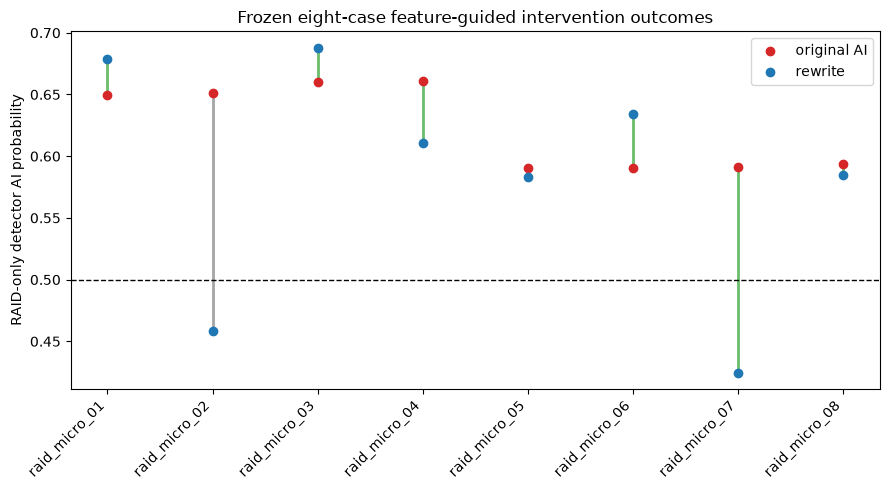

original exact contributions: 100%|█| 600/600 [00:0


maximum reconstruction error: 5.551115123125783e-16


treatment exact contributions: 100%|█| 600/600 [00:


maximum reconstruction error: 6.661338147750939e-16


feature_block,basic_absolute,basic_relative,conjunction_overlap,lexical_diversity,paragraph,pos_sentence_overlap,punctuation_per_sentence,punctuation_relative,readability,word_sentence_overlap
case_id,,,,,,,,,,
raid_micro_01,0.001263,0.000759,-0.000967,0.012241,0.000777,0.008292,0.001973,0.006652,0.000230,-0.002309
raid_micro_02,-0.000356,0.001604,-0.005520,-0.009940,0.000836,0.024546,-0.116170,-0.075703,0.011485,-0.024032
raid_micro_03,0.016285,0.024586,0.006659,0.029116,-0.002338,-0.002475,-0.013754,-0.035620,0.000834,0.004220
raid_micro_04,0.008057,0.007530,0.001420,0.000677,0.002675,-0.023802,-0.032410,-0.024681,0.011696,-0.001154
raid_micro_05,-0.013558,0.002390,0.011603,-0.017232,0.001648,0.030620,0.004159,-0.001821,0.003222,-0.028486
raid_micro_06,0.010580,0.019681,-0.005041,-0.036125,-0.001104,0.004057,0.009765,0.018307,0.013954,0.009120
raid_micro_07,-0.005277,0.002550,0.002582,-0.001022,-0.006268,-0.017860,-0.031448,-0.067764,-0.013746,-0.028232
raid_micro_08,-0.005172,0.017126,-0.001359,-0.021259,-0.000644,-0.008328,-0.000377,0.000673,0.023536,-0.013096


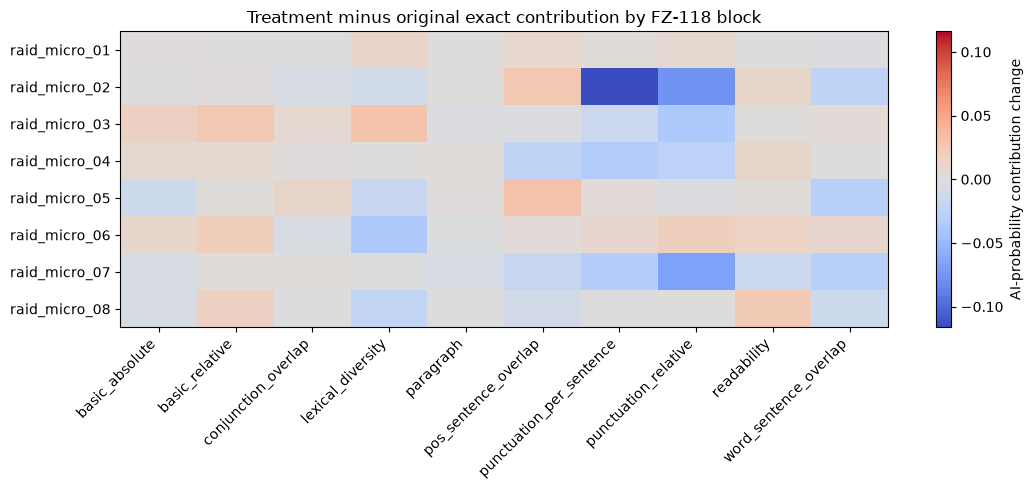

In [16]:
figure, axis = plt.subplots(figsize=(9, 5))
x = np.arange(len(treatment_audit))
for index in range(len(treatment_audit)):
    color = "tab:green" if treatment_audit.iloc[index]["valid_treatment"] else "tab:gray"
    axis.plot(
        [x[index], x[index]],
        [original_probability[index], treatment_probability[index]],
        color=color, alpha=0.7, linewidth=2,
    )
axis.scatter(x, original_probability, label="original AI", color="tab:red", zorder=3)
axis.scatter(x, treatment_probability, label="rewrite", color="tab:blue", zorder=3)
axis.axhline(0.5, color="black", linestyle="--", linewidth=1)
axis.set_xticks(x, treatment_audit["case_id"], rotation=45, ha="right")
axis.set_ylabel("RAID-only detector AI probability")
axis.set_title("Frozen eight-case feature-guided intervention outcomes")
axis.legend()
figure.tight_layout()
outcome_figure = OUT / "raid_micro_probability_changes.png"
figure.savefig(outcome_figure, dpi=200, bbox_inches="tight")
plt.show()

original_bias, original_contribution, original_check = (
    exact_forest_probability_contributions(
        raid_detector, original_rows, MODEL_FEATURES,
        "original exact contributions",
    )
)
treatment_bias, treatment_contribution, treatment_check = (
    exact_forest_probability_contributions(
        raid_detector, treatment_features, MODEL_FEATURES,
        "treatment exact contributions",
    )
)
assert abs(original_bias - treatment_bias) < 1e-12
contribution_change = treatment_contribution - original_contribution

contribution_change_rows = []
for row_index, case in treatment_audit.reset_index(drop=True).iterrows():
    for feature_index, feature in enumerate(MODEL_FEATURES):
        contribution_change_rows.append({
            "case_id": case["case_id"],
            "source_id": case["source_id"],
            "feature": feature,
            "feature_block": feature_to_block[feature],
            "contribution_change": contribution_change[row_index, feature_index],
        })
contribution_change_table = pd.DataFrame(contribution_change_rows)
contribution_change_table.to_csv(
    OUT / "raid_micro_exact_contribution_changes.csv", index=False
)

block_change = (
    contribution_change_table
    .groupby(["case_id", "feature_block"])["contribution_change"]
    .sum().unstack(fill_value=0.0)
)
display(block_change)

limit = float(np.abs(block_change.to_numpy()).max())
figure, axis = plt.subplots(figsize=(11, 5))
image = axis.imshow(
    block_change.to_numpy(), aspect="auto", cmap="coolwarm",
    vmin=-limit, vmax=limit,
)
axis.set_xticks(np.arange(block_change.shape[1]), block_change.columns, rotation=45, ha="right")
axis.set_yticks(np.arange(block_change.shape[0]), block_change.index)
axis.set_title("Treatment minus original exact contribution by FZ-118 block")
colorbar = figure.colorbar(image, ax=axis)
colorbar.set_label("AI-probability contribution change")
figure.tight_layout()
block_figure = OUT / "raid_micro_block_contribution_changes.png"
figure.savefig(block_figure, dpi=200, bbox_inches="tight")
plt.show()


## 12. Frozen audit record

The notebook reports the eight-case result without automatically authorizing scale.
A larger experiment requires a separate decision based on semantic validity,
direction consistency, and domain coverage.


In [17]:
audit_manifest = {
    "seed": SEED,
    "dataset": "raid",
    "ghostbuster_used": False,
    "adversarial_raid_rows_selected": 0,
    "layout_normalization": LAYOUT_NORMALIZATION_VERSION,
    "excluded_features": PARENTHESIS_FEATURES,
    "model_feature_count": len(MODEL_FEATURES),
    "specificity_targets": list(TARGET_SPECIFICITIES),
    "cases_per_band": CASES_PER_BAND,
    "selection_sha256": SELECTION_SHA256,
    "semantic_cosine_floor": SEMANTIC_COSINE_FLOOR,
    "n_requested": int(len(treatment_audit)),
    "n_valid": int(treatment_audit["valid_treatment"].sum()),
    "larger_run_authorized": False,
}
(OUT / "raid_micro_audit_manifest.json").write_text(
    json.dumps(audit_manifest, indent=2) + "\n",
    encoding="utf-8",
)
print(json.dumps(audit_manifest, indent=2))
print("\nMICRO-STUDY COMPLETE. Larger run remains locked.")


{
  "seed": 42,
  "dataset": "raid",
  "ghostbuster_used": false,
  "adversarial_raid_rows_selected": 0,
  "layout_normalization": "newline_to_space_v1",
  "excluded_features": [
    "punct_relative_lparen",
    "punct_relative_rparen",
    "punct_per_sentence_lparen",
    "punct_per_sentence_rparen"
  ],
  "model_feature_count": 114,
  "specificity_targets": [
    0.95,
    0.99
  ],
  "cases_per_band": 4,
  "selection_sha256": "30199fcc27d5b279ba98096f50d50e36b654ac06d93d77b29503e8e079664ed5",
  "semantic_cosine_floor": 0.9,
  "n_requested": 8,
  "n_valid": 7,
  "larger_run_authorized": false
}

MICRO-STUDY COMPLETE. Larger run remains locked.


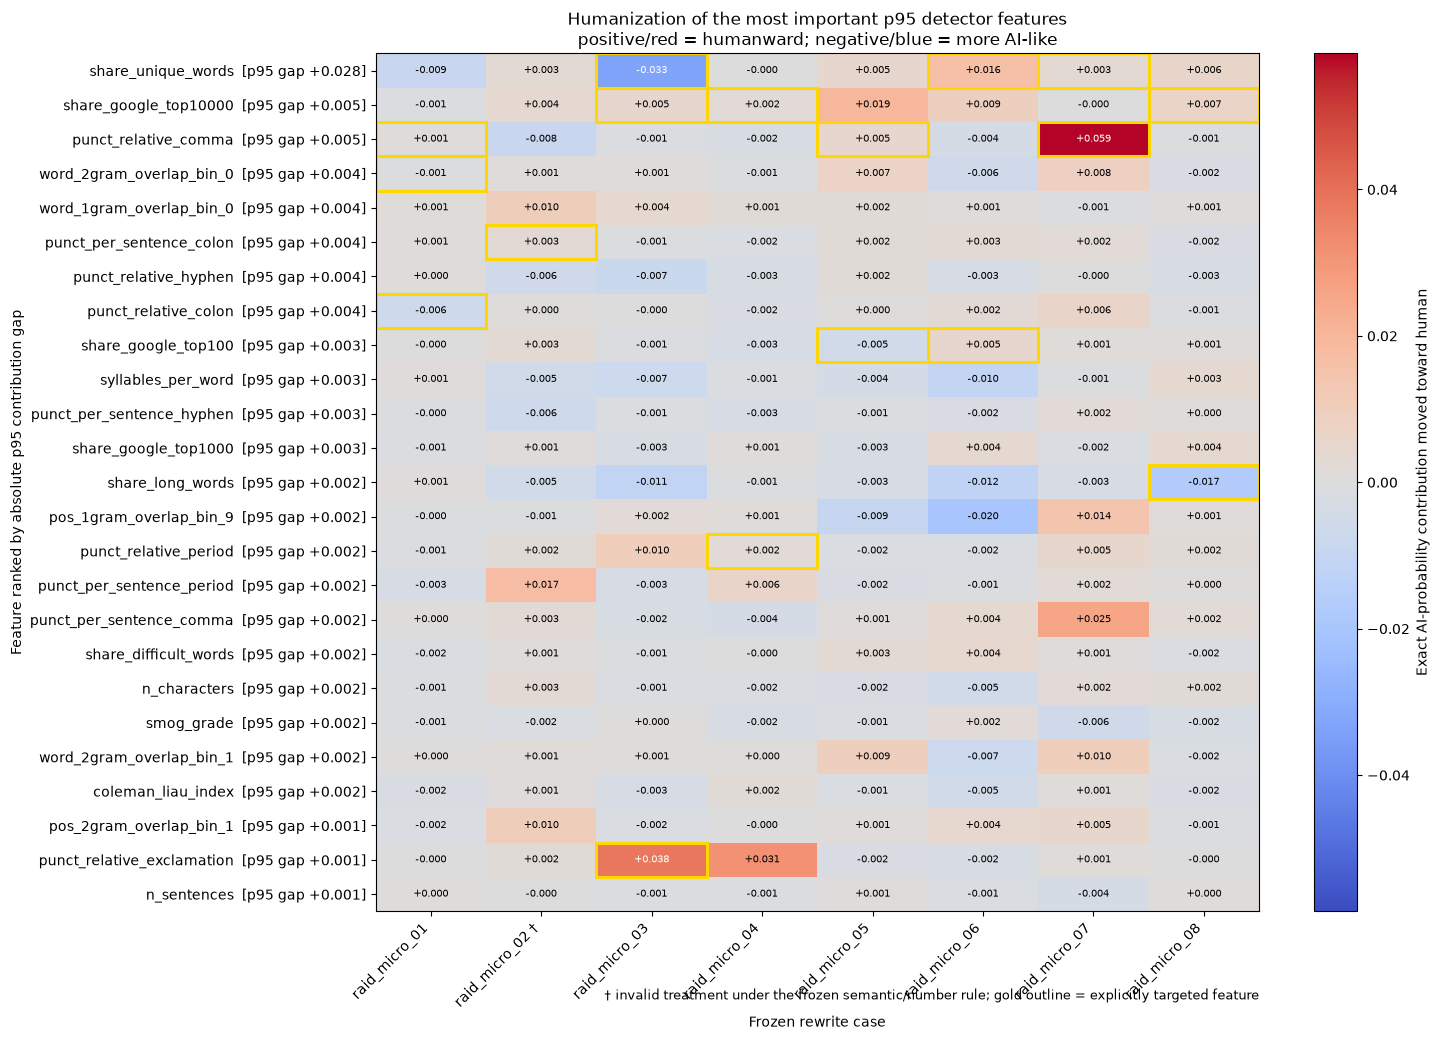

,feature,p95,p95_absolute_gap,mean_humanization_valid,median_humanization_valid,fraction_humanward_valid,n_times_targeted
0,share_unique_words,0.028326,0.028326,-0.001847,0.002962,0.571429,3
1,share_google_top10000,0.005134,0.005134,0.005794,0.004796,0.714286,3
2,punct_relative_comma,0.004670,0.004670,0.008136,-0.000547,0.428571,3
3,word_2gram_overlap_bin_0,0.004372,0.004372,0.000987,-0.000794,0.428571,1
4,word_1gram_overlap_bin_0,0.004081,0.004081,0.001384,0.001211,0.857143,0
5,punct_per_sentence_colon,0.003866,0.003866,0.000534,0.000856,0.571429,1
6,punct_relative_hyphen,0.003847,0.003847,-0.001935,-0.002565,0.285714,0
7,punct_relative_colon,0.003799,0.003799,-0.000102,-0.000087,0.428571,1
8,share_google_top100,0.003395,0.003395,-0.000466,-0.000442,0.428571,2
9,syllables_per_word,0.003033,0.003033,-0.002653,-0.000922,0.285714,0


saved: ../results/causal/C02e2_raid_feature_guided/raid_micro_p95_feature_humanization_heatmap.png


In [18]:
from matplotlib.patches import Rectangle

TOP_P95_FEATURES = 25

# Rank features by importance at the p95 operating point.
p95_ranked = contribution_gap[
    ["feature", "p95"]
].copy()

p95_ranked["p95_absolute_gap"] = p95_ranked["p95"].abs()
p95_ranked = (
    p95_ranked[
        p95_ranked["p95_absolute_gap"].gt(0)
    ]
    .sort_values(
        ["p95_absolute_gap", "feature"],
        ascending=[False, True],
    )
    .head(TOP_P95_FEATURES)
    .reset_index(drop=True)
)

model_feature_index = {
    feature: index
    for index, feature in enumerate(MODEL_FEATURES)
}

top_features = p95_ranked["feature"].tolist()
top_indices = np.array(
    [model_feature_index[feature] for feature in top_features],
    dtype=int,
)

p95_gap = p95_ranked["p95"].to_numpy(float)
p95_direction = np.sign(p95_gap)

# contribution_change is treatment minus original.
selected_contribution_change = contribution_change[:, top_indices]

# Positive = movement toward the p95 test-human contribution profile.
# Negative = movement farther in the p95 AI-associated direction.
humanization_matrix = (
    -selected_contribution_change
    * p95_direction[np.newaxis, :]
)

case_ids = treatment_audit["case_id"].astype(str).tolist()
valid_by_case = (
    treatment_audit
    .set_index("case_id")["valid_treatment"]
    .astype(bool)
    .to_dict()
)

case_labels = [
    case_id if valid_by_case.get(case_id, False)
    else f"{case_id} †"
    for case_id in case_ids
]

# Features as rows and cases as columns.
humanization_heatmap = pd.DataFrame(
    humanization_matrix.T,
    index=top_features,
    columns=case_ids,
)

# Long-form table for saving and later statistical analysis.
humanization_rows = []
targeted_pairs = set(
    zip(
        routing["case_id"].astype(str),
        routing["feature"].astype(str),
    )
)

for case_index, case_id in enumerate(case_ids):
    for feature_rank, feature in enumerate(top_features, start=1):
        feature_position = feature_rank - 1

        humanization_rows.append({
            "case_id": case_id,
            "valid_treatment": valid_by_case.get(case_id, False),
            "p95_importance_rank": feature_rank,
            "feature": feature,
            "p95_contribution_gap": p95_gap[feature_position],
            "p95_absolute_gap": abs(p95_gap[feature_position]),
            "contribution_change": selected_contribution_change[
                case_index, feature_position
            ],
            "humanization_effect": humanization_matrix[
                case_index, feature_position
            ],
            "humanward": bool(
                humanization_matrix[case_index, feature_position] > 0
            ),
            "targeted_in_prompt": (
                case_id,
                feature,
            ) in targeted_pairs,
        })

p95_humanization_long = pd.DataFrame(humanization_rows)

p95_humanization_long.to_csv(
    OUT / "raid_micro_p95_feature_humanization_long.csv",
    index=False,
)

humanization_heatmap.to_csv(
    OUT / "raid_micro_p95_feature_humanization_matrix.csv"
)

# Include the p95 reference gap in each feature label.
feature_labels = [
    f"{feature}  [p95 gap {gap:+.3f}]"
    for feature, gap in zip(top_features, p95_gap)
]

limit = float(np.abs(humanization_matrix).max())
if not np.isfinite(limit) or limit == 0:
    limit = 1e-12

figure, axis = plt.subplots(
    figsize=(15, max(9, 0.42 * len(top_features)))
)

image = axis.imshow(
    humanization_matrix.T,
    aspect="auto",
    cmap="coolwarm",
    vmin=-limit,
    vmax=limit,
)

axis.set_xticks(
    np.arange(len(case_ids)),
    case_labels,
    rotation=45,
    ha="right",
)

axis.set_yticks(
    np.arange(len(top_features)),
    feature_labels,
)

axis.set_xlabel("Frozen rewrite case")
axis.set_ylabel("Feature ranked by absolute p95 contribution gap")
axis.set_title(
    "Humanization of the most important p95 detector features\n"
    "positive/red = humanward; negative/blue = more AI-like"
)

# Annotate exact probability-contribution changes.
for feature_position in range(len(top_features)):
    for case_position in range(len(case_ids)):
        value = humanization_matrix[
            case_position,
            feature_position,
        ]

        text_color = (
            "white"
            if abs(value) > 0.55 * limit
            else "black"
        )

        axis.text(
            case_position,
            feature_position,
            f"{value:+.3f}",
            ha="center",
            va="center",
            fontsize=7,
            color=text_color,
        )

        # Gold outline = this exact feature was named in the prompt.
        if (
            case_ids[case_position],
            top_features[feature_position],
        ) in targeted_pairs:
            axis.add_patch(
                Rectangle(
                    (
                        case_position - 0.5,
                        feature_position - 0.5,
                    ),
                    1,
                    1,
                    fill=False,
                    edgecolor="gold",
                    linewidth=2.2,
                )
            )

colorbar = figure.colorbar(image, ax=axis)
colorbar.set_label(
    "Exact AI-probability contribution moved toward human"
)

axis.text(
    1.0,
    -0.09,
    "† invalid treatment under the frozen semantic/number rule; "
    "gold outline = explicitly targeted feature",
    transform=axis.transAxes,
    ha="right",
    va="top",
    fontsize=9,
)

figure.tight_layout()

p95_humanization_figure = (
    OUT / "raid_micro_p95_feature_humanization_heatmap.png"
)

figure.savefig(
    p95_humanization_figure,
    dpi=220,
    bbox_inches="tight",
)

plt.show()

# Aggregate each feature across the seven valid treatments.
valid_case_mask = (
    treatment_audit["valid_treatment"]
    .astype(bool)
    .to_numpy()
)

valid_humanization = humanization_matrix[valid_case_mask]

p95_feature_humanization_summary = p95_ranked.copy()
p95_feature_humanization_summary[
    "mean_humanization_valid"
] = np.mean(valid_humanization, axis=0)
p95_feature_humanization_summary[
    "median_humanization_valid"
] = np.median(valid_humanization, axis=0)
p95_feature_humanization_summary[
    "fraction_humanward_valid"
] = np.mean(valid_humanization > 0, axis=0)

p95_feature_humanization_summary[
    "n_times_targeted"
] = [
    sum(
        (case_id, feature) in targeted_pairs
        for case_id in case_ids
    )
    for feature in top_features
]

p95_feature_humanization_summary.to_csv(
    OUT / "raid_micro_p95_feature_humanization_summary.csv",
    index=False,
)

display(p95_feature_humanization_summary)

print("saved:", p95_humanization_figure)